# Clase 27 — Reglas de Probabilidad
### Versión explicada paso a paso

La idea de este notebook es que **nunca aparezca una fórmula sin que primero entendamos por qué existe**. Por eso, cada sección sigue el mismo esquema:

1. 🤔 **Intuición** — lo explicamos con palabras simples, sin números.
2. ✏️ **Fórmula** — recién ahí la escribimos matemáticamente.
3. 💻 **Código comentado** — la calculamos en Python, línea por línea.
4. 🔍 **Comprobación** — verificamos que la teoría coincide con la simulación o con los datos.

**Índice:**

0. Los 3 axiomas de la probabilidad
1. Experimento aleatorio y espacio muestral
2. Eventos, unión e intersección (con diagrama de Venn)
3. Ley de los Grandes Números (por qué la simulación se acerca a la teoría)
4. Complemento
5. El problema del cumpleaños (caso base)
6. Probabilidad condicional — los patitos
7. Teorema de Bayes
8. Tabla de contingencia
9. Para practicar

In [ ]:
# Librerías que vamos a usar en todo el notebook.
# No hace falta entenderlas todas ahora: las vamos presentando a medida que las usamos.
import numpy as np              # para simular tiradas de dado y hacer cuentas rápidas
import matplotlib.pyplot as plt # para graficar
import pandas as pd             # para trabajar con tablas (como una mini planilla de cálculo)

# Fijamos una "semilla" para el generador de números aleatorios.
# Esto hace que, aunque los números sean aleatorios, el resultado sea el MISMO
# cada vez que corremos el notebook. Es útil para poder explicar siempre sobre
# los mismos números.
rng = np.random.default_rng(seed=42)

print("Librerías cargadas. Generador aleatorio listo (semilla = 42).")

Librerías cargadas. Generador aleatorio listo (semilla = 42).


## 0. Los 3 axiomas de la probabilidad

Antes de calcular nada, conviene saber **de dónde salen** todas las reglas que vamos a usar. Toda la probabilidad moderna se apoya en solamente **3 reglas base** (los axiomas de Kolmogórov). Todo lo demás —unión, intersección, complemento, condicional, Bayes— se puede *demostrar* a partir de estas tres:

| Axioma | En palabras simples | Fórmula |
|---|---|---|
| 1. No negatividad | Una probabilidad nunca puede ser negativa (no existe "−20% de posibilidades") | $P(A) \geq 0$ |
| 2. Normalización | Algo del espacio muestral **siempre** ocurre, así que la probabilidad total es 1 (100%) | $P(\Omega) = 1$ |
| 3. Aditividad | Si dos eventos no pueden pasar al mismo tiempo (son disjuntos), la probabilidad de que pase "uno u otro" es la suma de sus probabilidades | $P(A \cup B) = P(A) + P(B)$ si $A \cap B = \emptyset$ |

👉 Todo lo que sigue en este notebook (unión con superposición, complemento, condicional, Bayes) son **consecuencias lógicas** de estas 3 reglas, aplicadas a distintos escenarios. Vale la pena tenerlas en mente como el "terreno firme" del que parte todo lo demás.

## 1. Experimento aleatorio y espacio muestral

### 🤔 Intuición
Un **experimento aleatorio** es cualquier acción cuyo resultado no podemos predecir con certeza, pero sí podemos listar **todos los resultados posibles**. Tirar un dado es el ejemplo clásico: no sabemos qué va a salir, pero sabemos que solo puede salir 1, 2, 3, 4, 5 o 6.

A ese listado completo de resultados posibles lo llamamos **espacio muestral**, y lo anotamos con la letra griega Ω (omega).

### ✏️ Fórmula
$$\Omega = \{1,2,3,4,5,6\}$$

### 💻 Código comentado
Vamos a simular 1000 tiradas de un dado usando la computadora, en vez de tirar un dado real 1000 veces.

In [ ]:
# rng.integers(low, high, size) genera números enteros aleatorios.
#   low=1  -> el número más chico que puede salir es 1
#   high=7 -> ¡ojo! high es EXCLUSIVO, es decir, el 7 nunca sale.
#             por eso los valores posibles terminan siendo 1,2,3,4,5,6
#   size=1000 -> queremos 1000 tiradas, no una sola
x = rng.integers(low=1, high=7, size=1000)

# Veamos las primeras 20 tiradas para "tocar" los datos antes de resumirlos
print("Primeras 20 tiradas simuladas:")
print(x[:20])
print()
print("En total simulamos", len(x), "tiradas.")

Primeras 20 tiradas simuladas:
[1 5 4 3 3 6 1 5 2 1 4 6 5 5 5 5 4 1 6 3]

En total simulamos 1000 tiradas.


In [ ]:
# np.unique cuenta, para cada valor distinto que aparece, cuántas veces se repite.
# return_counts=True hace que además del valor nos devuelva la cantidad de veces.
valores, frecuencias = np.unique(x, return_counts=True)

print("Valores posibles observados:", valores)
print("Cuántas veces salió cada uno:", frecuencias)
print()

# Si el dado es "justo", cada número debería salir aproximadamente 1000/6 veces
print("Si el dado fuera perfectamente justo, esperaríamos ~",
      round(1000 / 6, 1), "apariciones de cada valor.")

Valores posibles observados: [1 2 3 4 5 6]
Cuántas veces salió cada uno: [182 152 157 173 177 159]

Si el dado fuera perfectamente justo, esperaríamos ~ 166.7 apariciones de cada valor.


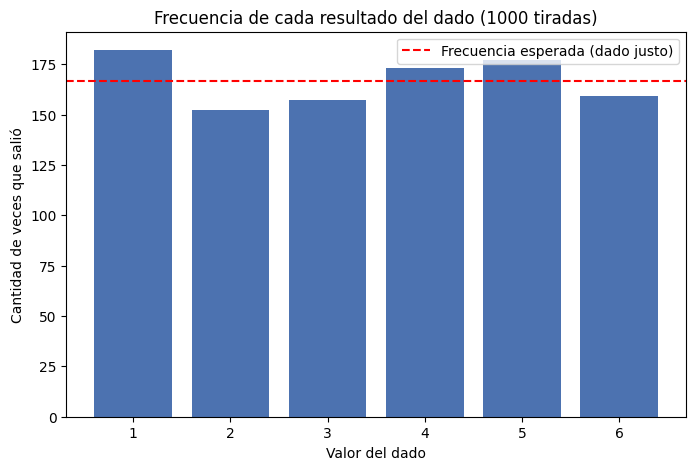

Espacio muestral Ω = {np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)}


In [ ]:
# Ahora sí, graficamos las frecuencias para verlas de un vistazo
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(valores, frecuencias, color="#4C72B0")

# Marcamos con una línea punteada lo que esperaríamos si el dado fuera perfecto
ax.axhline(1000 / 6, color="red", linestyle="--", label="Frecuencia esperada (dado justo)")

ax.set_title("Frecuencia de cada resultado del dado (1000 tiradas)")
ax.set_xlabel("Valor del dado")
ax.set_ylabel("Cantidad de veces que salió")
ax.legend()
plt.show()

print("Espacio muestral Ω =", set(valores))

### 🔍 Para pensar
Las barras no son *exactamente* iguales entre sí, aunque el dado sea justo. Eso es normal: con solo 1000 tiradas siempre hay algo de "ruido" aleatorio.

**Pregunta para reflexionar:** si en vez de 1000 tiradas simuláramos 1.000.000, ¿esperarías que las barras se parezcan más o menos entre sí? Vamos a volver sobre esta idea en la sección 3 (Ley de los Grandes Números).

## 2. Eventos, unión e intersección

### 🤔 Intuición
Un **evento** es simplemente un subconjunto del espacio muestral: un grupo de resultados que nos interesa agrupar porque comparten algo en común. Por ejemplo, "que salga un número par" no es un solo resultado, sino un *grupo* de resultados: {2, 4, 6}.

Vamos a definir dos eventos:

- **A** = "sale par" = {2, 4, 6}
- **B** = "sale más de 4" = {5, 6}

Y nos interesan dos formas de combinarlos:

- **Unión (A ∪ B):** pasa **A o B** (o ambos). Es "juntar" los dos conjuntos.
- **Intersección (A ∩ B):** pasa **A y B al mismo tiempo**. Es lo que tienen en común.

### 📊 Diagrama de Venn
Antes de calcular nada, veámoslo dibujado. Cada círculo es un evento, y donde se superponen está la intersección.

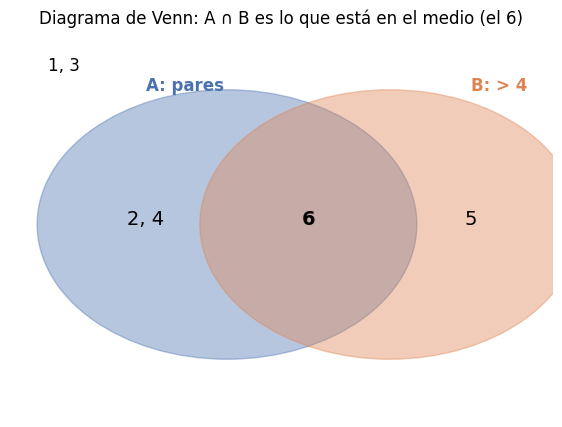

In [ ]:
from matplotlib.patches import Circle

fig, ax = plt.subplots(figsize=(7, 5))

# Dibujamos dos círculos superpuestos: uno para A y otro para B
circulo_A = Circle((0.4, 0.5), 0.35, alpha=0.4, color="#4C72B0")
circulo_B = Circle((0.7, 0.5), 0.35, alpha=0.4, color="#DD8452")
ax.add_patch(circulo_A)
ax.add_patch(circulo_B)

# Ubicamos cada número del espacio muestral en su zona correspondiente
ax.text(0.25, 0.5, "2, 4", fontsize=14, ha="center")   # solo en A
ax.text(0.85, 0.5, "5", fontsize=14, ha="center")      # solo en B
ax.text(0.55, 0.5, "6", fontsize=14, ha="center", weight="bold")  # en A y B (intersección)
ax.text(0.1, 0.9, "1, 3", fontsize=12, ha="center")    # ni en A ni en B

ax.text(0.25, 0.85, "A: pares", fontsize=12, color="#4C72B0", weight="bold")
ax.text(0.85, 0.85, "B: > 4", fontsize=12, color="#DD8452", weight="bold")

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")
ax.set_title("Diagrama de Venn: A ∩ B es lo que está en el medio (el 6)")
plt.show()

### 💻 Ahora lo mismo, pero calculado con código

In [ ]:
espacio_muestral = {1, 2, 3, 4, 5, 6}

A = {2, 4, 6}      # A: "sale par"
B = {5, 6}         # B: "sale más de 4"

# En Python, los conjuntos (sets) tienen operadores especiales:
#   |  -> unión      ("o")
#   &  -> intersección ("y")
union = A | B
interseccion = A & B

print("Paso 1 - Definimos los conjuntos:")
print("  A =", A)
print("  B =", B)
print()
print("Paso 2 - Los combinamos:")
print("  A ∪ B (unión)        =", union)
print("  A ∩ B (intersección) =", interseccion)

Paso 1 - Definimos los conjuntos:
  A = {2, 4, 6}
  B = {5, 6}

Paso 2 - Los combinamos:
  A ∪ B (unión)        = {2, 4, 5, 6}
  A ∩ B (intersección) = {6}


### ✏️ De los conjuntos a las probabilidades

Como el dado es "justo" (todos los resultados igual de probables), la probabilidad de un evento es simplemente:

$$P(\text{evento}) = \frac{\text{cantidad de resultados favorables}}{\text{cantidad total de resultados posibles}}$$

**Un detalle importante sobre la unión:** si simplemente sumáramos P(A) + P(B), estaríamos contando **dos veces** al 6 (porque está en ambos conjuntos). Por eso hay que *restar* la intersección una vez, para no duplicarla. Esa es la regla de adición:

$$P(A \cup B) = P(A) + P(B) - P(A \cap B)$$

In [ ]:
p_A = len(A) / len(espacio_muestral)
p_B = len(B) / len(espacio_muestral)
p_interseccion = len(interseccion) / len(espacio_muestral)

print(f"P(A) = {len(A)}/{len(espacio_muestral)} = {p_A:.3f}")
print(f"P(B) = {len(B)}/{len(espacio_muestral)} = {p_B:.3f}")
print(f"P(A ∩ B) = {len(interseccion)}/{len(espacio_muestral)} = {p_interseccion:.3f}")
print()

# Si sumáramos P(A) + P(B) sin restar nada, ¿qué pasaría?
suma_sin_corregir = p_A + p_B
print("Si solo sumáramos P(A) + P(B):", round(suma_sin_corregir, 3),
      "← esto está MAL, cuenta el 6 dos veces")

p_union_formula = p_A + p_B - p_interseccion
print("Restando la intersección una vez:", round(p_union_formula, 3),
      "← esto sí es correcto")

P(A) = 3/6 = 0.500
P(B) = 2/6 = 0.333
P(A ∩ B) = 1/6 = 0.167

Si solo sumáramos P(A) + P(B): 0.833 ← esto está MAL, cuenta el 6 dos veces
Restando la intersección una vez: 0.667 ← esto sí es correcto


## 3. Ley de los Grandes Números (comprobación empírica)

### 🤔 Intuición
Una cosa es la probabilidad **teórica** (la que calculamos con la fórmula) y otra es la **frecuencia observada** en una simulación. Cuantas más tiradas hacemos, más se parecen una a la otra. A este fenómeno se lo llama **Ley de los Grandes Números**.

Vamos a comprobarlo con nuestras 1000 tiradas guardadas en `x`.

In [ ]:
# np.isin(x, lista) devuelve un array de True/False:
# True en cada posición donde la tirada pertenece al conjunto dado
es_A = np.isin(x, list(A))
es_B = np.isin(x, list(B))

es_union = es_A | es_B          # True donde pasó A o B
es_interseccion = es_A & es_B   # True donde pasaron A y B a la vez

# El promedio de un array de True/False es exactamente la proporción de "True"
# (porque True vale 1 y False vale 0). Por eso .mean() nos da la frecuencia relativa.
print("                      Empírica   |   Teórica")
print(f"P(A)                = {es_A.mean():.3f}     |   {p_A:.3f}")
print(f"P(B)                = {es_B.mean():.3f}     |   {p_B:.3f}")
print(f"P(A ∩ B)            = {es_interseccion.mean():.3f}     |   {p_interseccion:.3f}")
print(f"P(A ∪ B)            = {es_union.mean():.3f}     |   {p_union_formula:.3f}")

                      Empírica   |   Teórica
P(A)                = 0.484     |   0.500
P(B)                = 0.336     |   0.333
P(A ∩ B)            = 0.159     |   0.167
P(A ∪ B)            = 0.661     |   0.667


### 📊 Viendo la convergencia en cámara lenta

En vez de mirar solo el resultado final con las 1000 tiradas, veamos **cómo va cambiando** la probabilidad de A a medida que acumulamos más tiradas. Al principio va a "saltar" mucho, y de a poco se va a ir estabilizando cerca del valor teórico (0.5).

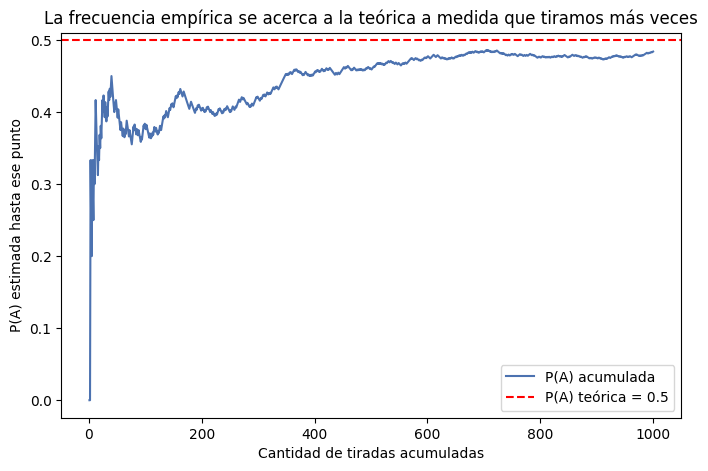

In [ ]:
# np.cumsum va sumando acumulativamente. Si lo dividimos por la cantidad de
# tiradas hechas hasta ese punto, obtenemos el "promedio hasta el momento"
cantidad_tiradas = np.arange(1, len(x) + 1)
promedio_acumulado = np.cumsum(es_A) / cantidad_tiradas

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(cantidad_tiradas, promedio_acumulado, color="#4C72B0", label="P(A) acumulada")
ax.axhline(p_A, color="red", linestyle="--", label=f"P(A) teórica = {p_A}")

ax.set_title("La frecuencia empírica se acerca a la teórica a medida que tiramos más veces")
ax.set_xlabel("Cantidad de tiradas acumuladas")
ax.set_ylabel("P(A) estimada hasta ese punto")
ax.legend()
plt.show()

## 4. Complemento

### 🤔 Intuición
El **complemento** de un evento A (anotado $A^c$) es "todo lo que NO es A", dentro del espacio muestral. Si A es "sale par", entonces $A^c$ es "sale impar".

Como el espacio muestral entero suma probabilidad 1 (axioma 2), y A y $A^c$ juntos forman todo el espacio muestral sin superponerse, se cumple:

$$P(A) + P(A^c) = 1 \quad\Longrightarrow\quad P(A^c) = 1 - P(A)$$

In [ ]:
# El operador "-" entre conjuntos en Python devuelve "lo que está en el primero
# pero no en el segundo" -> exactamente la definición de complemento
A_complemento = espacio_muestral - A

p_A_complemento = len(A_complemento) / len(espacio_muestral)

print("A  =", A, "→ 'sale par'")
print("Aᶜ =", A_complemento, "→ 'sale impar'")
print()
print(f"P(A)  = {p_A}")
print(f"P(Aᶜ) = {p_A_complemento}")
print(f"P(A) + P(Aᶜ) = {p_A + p_A_complemento}  ← siempre debe dar 1")

A  = {2, 4, 6} → 'sale par'
Aᶜ = {1, 3, 5} → 'sale impar'

P(A)  = 0.5
P(Aᶜ) = 0.5
P(A) + P(Aᶜ) = 1.0  ← siempre debe dar 1


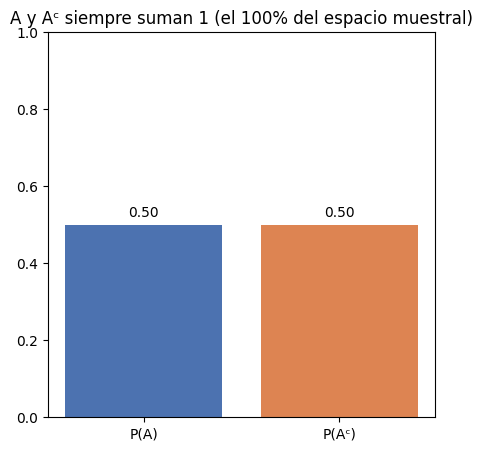

In [ ]:
# Lo vemos también como gráfico: A y Aᶜ tienen que "completar" el 100%
fig, ax = plt.subplots(figsize=(5, 5))
ax.bar(["P(A)", "P(Aᶜ)"], [p_A, p_A_complemento], color=["#4C72B0", "#DD8452"])
ax.set_ylim(0, 1)
ax.set_title("A y Aᶜ siempre suman 1 (el 100% del espacio muestral)")
for i, valor in enumerate([p_A, p_A_complemento]):
    ax.text(i, valor + 0.02, f"{valor:.2f}", ha="center")
plt.show()

## 5. El problema del cumpleaños (caso base)

### 🤔 Intuición
El famoso "problema del cumpleaños" pregunta: en un grupo de 30 personas, ¿cuál es la probabilidad de que **al menos dos** compartan la fecha de cumpleaños? La respuesta sorprende a mucha gente porque es mucho más alta de lo que la intuición sugiere (más del 70%).

Pero antes de llegar a ese cálculo (que requiere combinar muchas probabilidades condicionales), empecemos por el caso más chico posible: **2 personas**.

> Fijamos a una persona. ¿Cuál es la probabilidad de que otra persona cumpla años exactamente el mismo día que ella?

### ✏️ Fórmula
Hay 365 días posibles, y solo **1** coincide con el cumpleaños de la primera persona:

$$P(\text{mismo día}) = \frac{\text{casos favorables}}{\text{casos posibles}} = \frac{1}{365}$$

In [ ]:
dias_del_anio = 365
casos_favorables = 1   # solo el día exacto del cumpleaños de la primera persona cuenta

probabilidad_mismo_dia = casos_favorables / dias_del_anio

print("Casos favorables:", casos_favorables, "(un solo día exacto)")
print("Casos posibles:  ", dias_del_anio, "(cualquier día del año)")
print()
print("P(mismo cumpleaños) =", round(probabilidad_mismo_dia, 5))
print("En porcentaje        =", round(probabilidad_mismo_dia * 100, 3), "%")

Casos favorables: 1 (un solo día exacto)
Casos posibles:   365 (cualquier día del año)

P(mismo cumpleaños) = 0.00274
En porcentaje        = 0.274 %


⚠️ **Ojo con esta distinción:** esto **no** es todavía el problema de las 30 personas. Acá solo comparamos 2 personas. El problema completo involucra comparar a cada persona con todas las demás (¡son muchas más comparaciones posibles de lo que parece!), y por eso la probabilidad final termina siendo mucho más alta. Este cálculo simple es la "semilla" para entender ese problema más adelante.

## 6. Probabilidad condicional — los patitos

### 🤔 Intuición
La probabilidad condicional responde a la pregunta: *"si ya sé algo sobre el resultado, ¿cambia la probabilidad de otra cosa?"*

Imaginemos que tenemos 20 patitos. Algunos son domésticos, otros salvajes; algunos son hembra, otros macho. Nos interesa:

$$P(H \mid D) = \text{"probabilidad de que sea hembra, sabiendo que ya es doméstico"}$$

El símbolo " | " se lee **"dado que"**. Es la clave de toda probabilidad condicional: la información de la derecha del "|" **reduce el universo** en el que buscamos.

### 🦆 Primero, a nivel individual
En vez de arrancar con números agregados, construyamos los 20 patitos uno por uno, como si fuera una lista real de animales. Así se ve más claro qué significa "filtrar".

In [ ]:
# Creamos una lista con los 20 patitos, cada uno con su tipo y su sexo.
# (Los números coinciden con la tabla que vamos a construir más abajo:
#  8 hembras domésticas, 5 machos domésticos, 4 hembras salvajes, 3 machos salvajes)
patitos = (
    [{"tipo": "Doméstico", "sexo": "Hembra"}] * 8 +
    [{"tipo": "Doméstico", "sexo": "Macho"}]  * 5 +
    [{"tipo": "Salvaje",   "sexo": "Hembra"}] * 4 +
    [{"tipo": "Salvaje",   "sexo": "Macho"}]  * 3
)

df_patitos = pd.DataFrame(patitos)

print("Tenemos", len(df_patitos), "patitos en total. Así se ven los primeros 6:")
df_patitos.head(6)

Tenemos 20 patitos en total. Así se ven los primeros 6:


,tipo,sexo
0,Doméstico,Hembra
1,Doméstico,Hembra
2,Doméstico,Hembra
3,Doméstico,Hembra
4,Doméstico,Hembra
5,Doméstico,Hembra


In [ ]:
# P(H): de TODOS los 20 patitos, ¿qué proporción es hembra?
p_H = (df_patitos["sexo"] == "Hembra").mean()
print(f"P(H) sobre los 20 patitos = {p_H:.3f}")
print()

# Ahora, para P(H | D), primero nos QUEDAMOS SOLO con los domésticos
# (esto es literalmente "reducir el universo" del que hablábamos)
solo_domesticos = df_patitos[df_patitos["tipo"] == "Doméstico"]
print("De los 20 patitos, solo", len(solo_domesticos), "son domésticos.")
print("Ese subconjunto es nuestro nuevo 'mundo' para calcular P(H | D):")
print()

# Y ahí adentro, ¿qué proporción es hembra?
p_H_dado_D = (solo_domesticos["sexo"] == "Hembra").mean()
print(f"P(H | D) = {(solo_domesticos['sexo'] == 'Hembra').sum()}/{len(solo_domesticos)} = {p_H_dado_D:.3f}")

P(H) sobre los 20 patitos = 0.600

De los 20 patitos, solo 13 son domésticos.
Ese subconjunto es nuestro nuevo 'mundo' para calcular P(H | D):

P(H | D) = 8/13 = 0.615


💡 **La idea clave, resumida:** P(H) mira los 20 patitos. P(H | D) **ya no mira los 20**: mira solamente los 13 domésticos. Por eso el denominador cambia de 20 a 13, y por eso el resultado también cambia (de 0.60 a ~0.615).

### ✏️ La fórmula general
Lo que acabamos de hacer "a mano" (filtrar y después calcular la proporción) es exactamente lo que dice la fórmula formal:

$$P(H \mid D) = \frac{P(H \cap D)}{P(D)}$$

Es decir: de todos los casos donde se cumple D (el nuevo universo), ¿qué proporción también cumple H?

## 7. Teorema de Bayes

### 🤔 Intuición
A veces conocemos una probabilidad condicional, pero necesitamos **la contraria** (la condición "al revés"). Por ejemplo: sabemos $P(H \mid D)$ (probabilidad de hembra sabiendo que es doméstico), pero queremos $P(D \mid H)$ (probabilidad de ser doméstico sabiendo que es hembra).

Estas dos probabilidades **no son lo mismo**, y confundirlas es uno de los errores más comunes en probabilidad. El Teorema de Bayes es la fórmula que nos permite "dar vuelta" la condición de manera correcta.

### ✏️ Fórmula
$$P(D \mid H) = \frac{P(H \mid D) \cdot P(D)}{P(H)}$$

**Cómo leerla en palabras:**
- $P(H \mid D)$: lo que ya sabíamos (evidencia dado la hipótesis)
- $P(D)$: qué tan común es D en general, antes de mirar nada más (probabilidad "a priori")
- $P(H)$: qué tan común es H en general (nos sirve para "reescalar" el resultado)
- $P(D \mid H)$: lo que queríamos calcular (la condición invertida)

In [ ]:
# Reutilizamos lo que ya calculamos antes con los patitos
P_H_dado_D = 8 / 13   # lo que ya sabíamos (sección 6)
P_D = 13 / 20         # proporción de domésticos en el total
P_H = 12 / 20         # proporción de hembras en el total

print("Ingredientes que ya teníamos:")
print(f"  P(H | D) = {P_H_dado_D:.3f}")
print(f"  P(D)     = {P_D:.3f}")
print(f"  P(H)     = {P_H:.3f}")
print()

# Aplicamos la fórmula de Bayes paso a paso
numerador = P_H_dado_D * P_D
P_D_dado_H = numerador / P_H

print("Paso 1 - Numerador: P(H|D) × P(D) =", round(numerador, 3))
print("Paso 2 - Dividimos por P(H):", round(numerador, 3), "/", round(P_H, 3))
print()
print(f"Resultado: P(D | H) = {P_D_dado_H:.3f} → {P_D_dado_H*100:.1f}%")

Ingredientes que ya teníamos:
  P(H | D) = 0.615
  P(D)     = 0.650
  P(H)     = 0.600

Paso 1 - Numerador: P(H|D) × P(D) = 0.4
Paso 2 - Dividimos por P(H): 0.4 / 0.6

Resultado: P(D | H) = 0.667 → 66.7%


🔍 **Comprobemos que tiene sentido:** en la sección 6 vimos, a mano, que de los 12 patitos hembra, 8 eran domésticos. Entonces $P(D \mid H)$ debería dar $8/12 = 0.667$ — exactamente lo que obtuvimos con la fórmula de Bayes. 🎉

## 8. Tabla de contingencia

### 🤔 Intuición
Todo lo que hicimos en las secciones 6 y 7 se puede resumir en **una sola tabla**, cruzando las dos características (tipo y sexo). Esto es justamente lo que se llama **tabla de contingencia**, y es la herramienta que más se usa en la práctica para trabajar con probabilidad condicional y Bayes al mismo tiempo.

In [ ]:
# pd.crosstab cuenta automáticamente, cruzando dos columnas, cuántos casos hay
# en cada combinación. Es exactamente construir la tabla "a mano" pero en una línea.
tabla = pd.crosstab(df_patitos["tipo"], df_patitos["sexo"], margins=True, margins_name="Total")
tabla

sexo,Hembra,Macho,Total
tipo,,,
Doméstico,8,5,13
Salvaje,4,3,7
Total,12,8,20


Leamos la tabla: cada celda interior es un cruce (por ejemplo, "Doméstico" + "Hembra" = 8). La columna y la fila "Total" suman los márgenes. A partir de acá podemos recalcular **cualquier** probabilidad que necesitemos, sin volver a contar patito por patito.

In [ ]:
# Extraemos los valores de la tabla usando .loc[fila, columna]
hembras_domesticas = tabla.loc["Doméstico", "Hembra"]
total_domesticos = tabla.loc["Doméstico", "Total"]

total_hembras = tabla.loc["Total", "Hembra"]
total_patitos = tabla.loc["Total", "Total"]

P_H_dado_D = hembras_domesticas / total_domesticos
P_D = total_domesticos / total_patitos
P_H = total_hembras / total_patitos
P_D_dado_H = (P_H_dado_D * P_D) / P_H

print("Todo recalculado directamente desde la tabla:")
print("  P(H | D) =", round(P_H_dado_D, 3))
print("  P(D | H) =", round(P_D_dado_H, 3))
print()
print("✅ Coincide con lo que calculamos antes 'a mano' con la lista de patitos.")

Todo recalculado directamente desde la tabla:
  P(H | D) = 0.615
  P(D | H) = 0.667

✅ Coincide con lo que calculamos antes 'a mano' con la lista de patitos.


## 9. Para practicar

Antes de cerrar, probá resolver estas preguntas usando el mismo código de arriba como referencia. La idea no es memorizar fórmulas, sino poder reconstruir el razonamiento.

1. Usando el dado (sección 2), definí un nuevo evento **C = "sale menos de 3"**. Calculá $P(C)$, $P(A \cup C)$ y $P(A \cap C)$.
2. Con la tabla de patitos, calculá $P(M \mid S)$ (probabilidad de ser macho, dado que es salvaje).
3. Aplicando Bayes, calculá $P(S \mid M)$ (probabilidad de ser salvaje, dado que es macho) y comprobá el resultado "a mano" filtrando `df_patitos`, como hicimos en la sección 6.

👇 Usá esta celda vacía para experimentar:

In [ ]:
# Tu código acá 👇


## Resumen final

| Regla | Fórmula | De dónde sale |
|---|---|---|
| Adición (unión) | $P(A \cup B) = P(A) + P(B) - P(A \cap B)$ | Axioma 3, corrigiendo el doble conteo de la intersección |
| Complemento | $P(A^c) = 1 - P(A)$ | Axiomas 2 y 3 combinados |
| Condicional | $P(A \mid B) = \dfrac{P(A \cap B)}{P(B)}$ | Definición: "reducir el universo" a B |
| Bayes | $P(A \mid B) = \dfrac{P(B \mid A)\, P(A)}{P(B)}$ | Se deduce igualando dos formas de escribir $P(A \cap B)$ |

Todo lo que vimos hoy se apoya, en el fondo, en los 3 axiomas de la sección 0. Si alguna fórmula se te complica recordarla, siempre podés volver a construirla desde la intuición: *"¿qué universo estoy mirando?"* y *"¿estoy contando algo dos veces?"*